# 2D X-Ray Diffraction (XRD) Integration and Rietveld Refinement of Nickel (Ni): Dual-Methodology Workflow

This notebook demonstrates the complete, end-to-end data processing and Rietveld structural refinement of high-energy 2D powder X-ray diffraction data for metallic Nickel (**Ni**). 

Instead of relying on a single approach, this combined notebook illustrates **two complementary methodologies** side-by-side across every phase of the analytical workflow:
1. **Methodology A (High-Level / Idiomatic `easyXRD`)**: A streamlined, modular pipeline leveraging `easyXRD`'s unified API for rapid data reduction, progressive Le Bail-to-Rietveld refinement, and microstructural size/strain modeling.
2. **Methodology B (Deep Diagnostic / Scriptable Pipeline)**: An in-depth, rigorous protocol employing direct `pyFAI`, `GSASIIscriptable`, `pymatgen`, and `scipy` for granular data inspection, multi-format export, Bragg indexing discrepancy analysis, direct instrumental profile refinement, diagnostic parameter boundary checks, covariance correlation analysis, and multi-panel publication diagnostics.

### Analytical Stages:
- **Section 1**: Environment Configuration, Provenance, & File Integrity
- **Section 2**: Raw 2D Detector Image & Mask Inspection *(Fabio visualization vs pyFAI calibration & instrument metadata)*
- **Section 3**: 2D-to-1D Azimuthal Integration & 1D Profile Archival *(easyXRD load & export vs direct pyFAI integration, 2D cake map, & multi-format export)*
- **Section 4**: Crystal Structure & Phase Identification *(easyXRD reflection overlay vs pymatgen XRDCalculator & scipy peak matching)*
- **Section 5**: Multi-Stage Rietveld Refinement Protocols *(Strategy A: Progressive Le Bail-to-Rietveld with sample broadening vs Strategy B: Direct Rietveld with profile U,V,W,X,Y & analytic Jacobian polishing)*
- **Section 6**: Advanced Validation, Covariance Analysis, & Multi-Panel Visualization *(easyXRD native summary vs manual Rwp recalculation, covariance matrix analysis, & 3-panel publication plots)*
- **Section 7**: Archival, Project Verification, & Provenance Tracking
- **Section 8**: Summary & Scientific Conclusions

In [1]:
# Environment configuration, library imports, and integrity verification
import os
import sys
import json
import copy
import shutil
import hashlib
from pathlib import Path
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import fabio
import pyFAI
from GSASII import GSASIIscriptable as G2sc
from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from scipy.signal import find_peaks

# Import easyXRD core
from easyxrd.core import exrd

# Base working directory and dedicated output directory
BASE = Path.cwd().resolve()
OUT = BASE / "Ni_combined_results"
OUT.mkdir(exist_ok=True)

# GSAS-II scratch directory and caching configuration
os.environ["EASYXRD_SCRATCH"] = str(OUT / "gsas_work")
os.environ.setdefault("NUMBA_CACHE_DIR", str(OUT / ".numba_cache"))
os.environ.setdefault("MPLCONFIGDIR", str(OUT / ".mpl_cache"))
os.environ.setdefault("OMP_NUM_THREADS", "4")

# Configure plotting parameters
%matplotlib inline
plt.rcParams.update({"figure.dpi": 115, "figure.constrained_layout.use": True, "font.size": 10})

# Verify presence and SHA-256 hashes of required input files
required_files = ["Ni.tiff", "_calibration.poni", "_mask.edf", "Ni.cif", "_instrument_parameters.gpx"]
assert all((BASE / f).is_file() for f in required_files), f"Missing required input files in {BASE}"
input_hashes = {f: hashlib.sha256((BASE / f).read_bytes()).hexdigest() for f in required_files}

# Record environment versions
versions = {
    "python": sys.version.split()[0],
    "executable": sys.executable,
    "pyFAI": pyFAI.version,
    "fabio": fabio.version,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "GSASII_module": G2sc.__file__,
}
for pkg in ["easyxrd", "scipy", "pymatgen"]:
    try:
        versions[pkg] = metadata.version(pkg)
    except metadata.PackageNotFoundError:
        versions[pkg] = "installed"

print("Environment initialized successfully. Recorded library versions:")
print(json.dumps(versions, indent=2))

GSAS-II binaries co-located with GSAS-II: /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII
N.B. Configuration file /home/mt/.GSASII/config.ini does not exist
0 values read from /home/mt/.GSASII/config.ini


Environment initialized successfully. Recorded library versions:
{
  "python": "3.14.8",
  "executable": "/home/mt/mpixi/.pixi/envs/default/bin/python",
  "pyFAI": "2026.9.0",
  "fabio": "2026.6.0",
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "GSASII_module": "/home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII/GSASIIscriptable.py",
  "easyxrd": "2026.9.20",
  "scipy": "1.18.1",
  "pymatgen": "2026.9.24"
}


## Section 2: Raw 2D Detector Image and Mask Inspection

Before azimuthal integration, we inspect the raw area detector image (`Ni.tiff`) and pixel mask (`_mask.edf`).
- **Approach 2.1 (Streamlined Fabio / easyXRD Visualization)**: Inspect detector counts and bad-pixel masking flags using `fabio` and matplotlib side-by-side.
- **Approach 2.2 (Deep Diagnostic Inspection & Instrument Metadata)**: Parse experimental geometry from `_calibration.poni` using `pyFAI`, load instrument baseline parameters from `_instrument_parameters.gpx` via `GSASIIscriptable`, quantify masked pixel percentages, and display a percentile-stretched masked detector array.

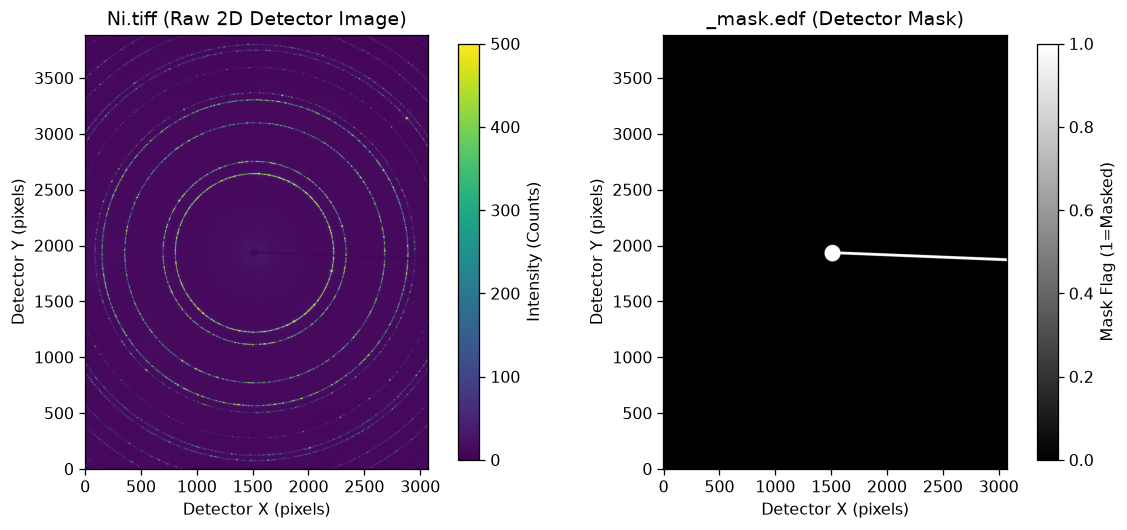

In [2]:
# Approach 2.1: Streamlined detector image and mask inspection with fabio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

img_data = fabio.open(str(BASE / "Ni.tiff")).data
im1 = ax1.imshow(img_data, vmin=0, vmax=500, cmap="viridis", origin="lower")
ax1.set_title("Ni.tiff (Raw 2D Detector Image)")
ax1.set_xlabel("Detector X (pixels)")
ax1.set_ylabel("Detector Y (pixels)")
plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, label="Intensity (Counts)")

mask_data = fabio.open(str(BASE / "_mask.edf")).data
im2 = ax2.imshow(mask_data, cmap="gray", origin="lower")
ax2.set_title("_mask.edf (Detector Mask)")
ax2.set_xlabel("Detector X (pixels)")
ax2.set_ylabel("Detector Y (pixels)")
plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="Mask Flag (1=Masked)")

plt.show()

### Alternative / Complementary Inspection: Approach 2.2
In addition to the raw image visualization above, we now inspect the physical calibration metadata, the baseline instrument parameters stored in `_instrument_parameters.gpx`, and display downsampled masked arrays with percentile scaling.

Detector dimensions : 3888 × 3072 pixels
Masked pixels       : 54,514 / 11,943,936 (0.456%)
Calibrated λ        : 0.179900 Å (energy ≈ 68.92 keV)
Sample-to-detector  : 0.599497 m (599.50 mm)


,parameter,reference_value
0,Type,PXC
1,Bank,1.0
2,Lam,0.1799
3,Polariz.,0.0
4,Azimuth,0.0
5,Zero,0.0
6,U,-29.429568
7,V,13.791336
8,W,0.870891
9,X,0.07517


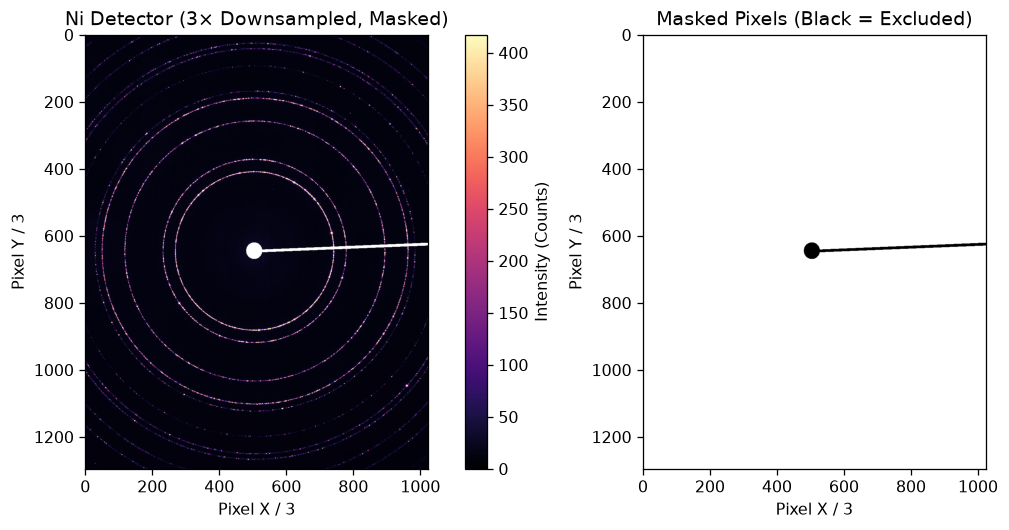

In [3]:
# Approach 2.2: Deep diagnostic calibration & instrument parameter inspection
image = fabio.open(str(BASE / "Ni.tiff")).data.astype(np.float32)
provided_mask = fabio.open(str(BASE / "_mask.edf")).data != 0
mask = provided_mask | ~np.isfinite(image)

# Load pyFAI calibration geometry
ai = pyFAI.load(str(BASE / "_calibration.poni"))
wavelength = ai.wavelength * 1e10  # Convert meters to Angstroms

# Load reference instrument parameters from GSAS-II GPX
reference_gpx = G2sc.G2Project(gpxfile=str(BASE / "_instrument_parameters.gpx"))
reference_hist = reference_gpx.histograms()[0]
reference_inst = copy.deepcopy(reference_hist.data["Instrument Parameters"][0])

print(f"Detector dimensions : {image.shape[0]} × {image.shape[1]} pixels")
print(f"Masked pixels       : {mask.sum():,} / {mask.size:,} ({100 * mask.mean():.3f}%)")
print(f"Calibrated λ        : {wavelength:.6f} Å (energy ≈ {12.3984 / wavelength:.2f} keV)")
print(f"Sample-to-detector  : {ai.dist:.6f} m ({ai.dist * 1e3:.2f} mm)")

# Display reference instrument parameters table
display(pd.DataFrame([{"parameter": k, "reference_value": v[1]} for k, v in reference_inst.items()]).head(10))

# Display downsampled 3x image with percentile clipping for ring visibility
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
view = np.ma.array(image[::3, ::3], mask=mask[::3, ::3])
im = axes[0].imshow(view, origin="upper", vmin=0, vmax=np.percentile(image[~mask], 99.5), cmap="magma")
axes[0].set(title="Ni Detector (3× Downsampled, Masked)", xlabel="Pixel X / 3", ylabel="Pixel Y / 3")
fig.colorbar(im, ax=axes[0], label="Intensity (Counts)")

axes[1].imshow(mask[::3, ::3], origin="upper", cmap="gray_r", vmin=0, vmax=1)
axes[1].set(title="Masked Pixels (Black = Excluded)", xlabel="Pixel X / 3", ylabel="Pixel Y / 3")
fig.savefig(OUT / "Ni_detector_and_mask_diagnostic.png", dpi=180)
plt.show()

## Section 3: 2D-to-1D Azimuthal Integration & Profile Archival

Next, we convert 2D area detector rings into a 1D powder diffraction profile $I(q)$ vs $q$ (or $2\theta$).
- **Approach 3.1 (easyXRD High-Level Pipeline)**: Use `sample.load_xrd_data(...)` with integrated log-scale configuration and export to `.xy`.
- **Approach 3.2 (Direct pyFAI Integration, 2D Cake Map, & Multi-Format Export)**: Perform direct azimuthal integration with `ai.integrate1d`, inspect 2D polar cake $(q, \chi)$ for texture/spotty ring inspection, and export multi-column CSV and `.xye` files with weighting proxies.

Exported easyXRD 1D profile to: /home/mt/repos/easyXRD_with_agents/00-Ni/_combined_with_Gemini-3.8-Flash-High/Ni_combined_results/Ni_1D_streamlined.xy


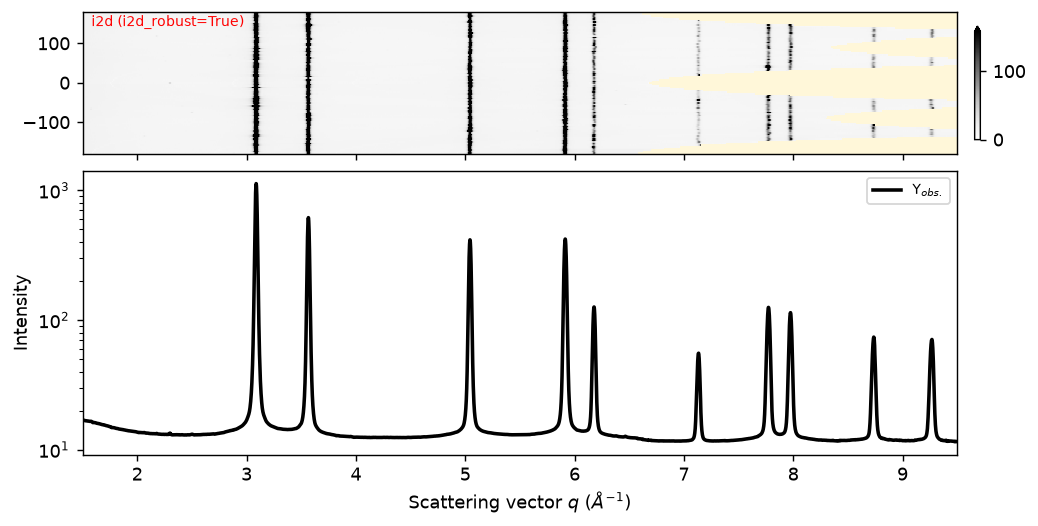

In [4]:
# Approach 3.1: Streamlined 2D-to-1D integration using easyXRD
sample_a = exrd(i1d_ylogscale=True, i2d_logscale=False)

# Load 2D diffraction image and integrate to 1D over [1.5, 9.5] Å⁻¹
sample_a.load_xrd_data(
    from_tiff_file=str(BASE / "Ni.tiff"),
    poni_file=str(BASE / "_calibration.poni"),
    mask_file=str(BASE / "_mask.edf"),
    radial_range=[1.5, 9.5],
)

# Export standard ASCII 1D profile data
sample_a.export_i1d_to(to=str(OUT / "Ni_1D_streamlined.xy"), mode="xy")
print(f"Exported easyXRD 1D profile to: {OUT / 'Ni_1D_streamlined.xy'}")

### Alternative / Complementary Integration: Approach 3.2
Here, we demonstrate direct `pyFAI` integration with explicit pixel-solid-angle correction, azimuthal error estimation, polar caking $(q, \chi)$, and export into multiple research formats (`.csv`, `.xy`, and weighted `.xye`).

Exported 2475 bins over q = 0.502–10.398 Å⁻¹ (2θ = 0.824–17.121°)


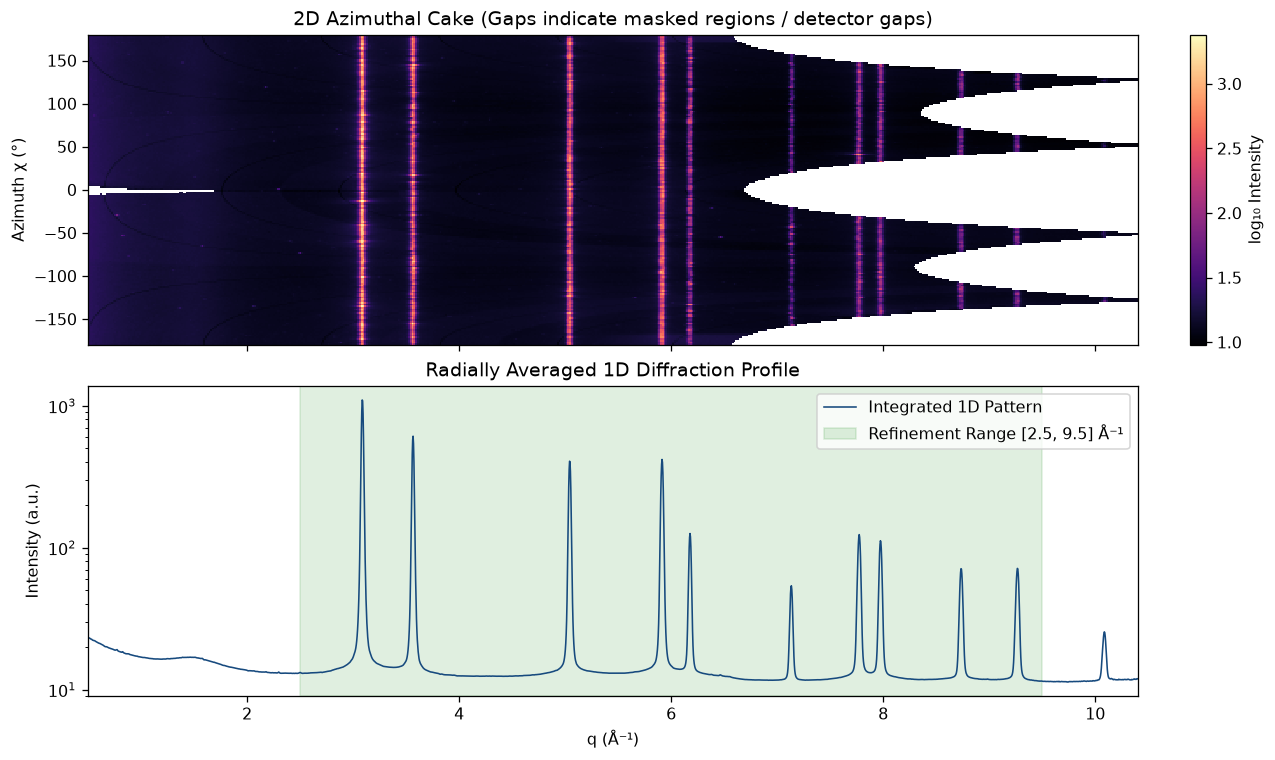

In [5]:
# Approach 3.2: Direct pyFAI azimuthal integration, 2D polar cake, and multi-format export
Q_RANGE = [0.5, 10.4]
DELTA_Q = 0.004
FIT_RANGE = [2.5, 9.5]
method = ("bbox", "csr", "cython")

# Integrate full range with easyXRD using pyFAI calibration object
full_b = exrd()
full_b.load_xrd_data(
    from_tiff_file=str(BASE / "Ni.tiff"),
    ai=ai,
    mask=mask,
    integrate2d=False,
    radial_range=Q_RANGE,
    delta_q=DELTA_Q,
    method=method,
    ds_attrs={},
    plot=False,
)

q_arr = full_b.ds.i1d.radial.values.astype(float)
y_arr = full_b.ds.i1d.values.astype(float)
tth_arr = np.degrees(2 * np.arcsin(q_arr * wavelength / (4 * np.pi)))

# Direct pyFAI integration with azimuthal error model for diagnostic comparison
ai.empty = np.nan
az = ai.integrate1d(
    image,
    npt=len(q_arr),
    radial_range=Q_RANGE,
    mask=mask,
    unit="q_A^-1",
    method=method,
    error_model="azimuthal",
    correctSolidAngle=True,
    polarization_factor=None,
)

assert np.allclose(q_arr, az.radial, atol=1e-6)
assert np.allclose(y_arr, az.intensity, rtol=1e-6)
assert np.all(np.isfinite(y_arr)) and np.all(az.count > 0)

sigma_proxy = np.sqrt(np.maximum(y_arr, 1.0))

# Multi-format exports
profile_df = pd.DataFrame({
    "q_A^-1": q_arr,
    "two_theta_deg": tth_arr,
    "intensity_au": y_arr,
    "sigma_weight_proxy": sigma_proxy,
    "sigma_azimuthal_diagnostic": az.sigma,
    "effective_pixel_count": az.count,
})
profile_df.to_csv(OUT / "Ni_integrated_profile.csv", index=False)
np.savetxt(OUT / "Ni_2theta.xy", np.c_[tth_arr, y_arr], header=f"two_theta_deg intensity_au; wavelength_A={wavelength:.6f}")
np.savetxt(OUT / "Ni_q.xy", np.c_[q_arr, y_arr], header="q_A^-1 intensity_au")
np.savetxt(OUT / "Ni_2theta.xye", np.c_[tth_arr, y_arr, sigma_proxy], header="two_theta_deg intensity_au sigma_proxy")
print(f"Exported {len(q_arr)} bins over q = {q_arr.min():.3f}–{q_arr.max():.3f} Å⁻¹ (2θ = {tth_arr.min():.3f}–{tth_arr.max():.3f}°)")

# Generate 2D azimuthal cake (q vs azimuth angle chi)
cake = ai.integrate2d(
    image,
    npt_rad=600,
    npt_azim=180,
    radial_range=Q_RANGE,
    mask=mask,
    unit="q_A^-1",
    method=method,
    correctSolidAngle=True,
    polarization_factor=None,
)

# Visualize 2D polar cake and 1D profile
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
pc = axes[0].pcolormesh(
    cake.radial,
    cake.azimuthal,
    np.ma.masked_invalid(np.log10(np.maximum(cake.intensity, 1))),
    shading="auto",
    cmap="magma",
)
axes[0].set(ylabel="Azimuth χ (°)", title="2D Azimuthal Cake (Gaps indicate masked regions / detector gaps)")
fig.colorbar(pc, ax=axes[0], label="log₁₀ Intensity")

axes[1].semilogy(q_arr, y_arr, lw=1, color="#174a7e", label="Integrated 1D Pattern")
axes[1].axvspan(*FIT_RANGE, alpha=0.12, color="green", label="Refinement Range [2.5, 9.5] Å⁻¹")
axes[1].set(xlabel="q (Å⁻¹)", ylabel="Intensity (a.u.)", title="Radially Averaged 1D Diffraction Profile")
axes[1].legend(loc="upper right")
fig.savefig(OUT / "Ni_integration_and_cake.png", dpi=180)
plt.show()

## Section 4: Crystal Structure & Phase Identification

We load the crystallographic structure of Nickel from `Ni.cif`:
- **Space Group**: $Fm\bar{3}m$ (No. 225, Face-Centered Cubic)
- **Initial Lattice Constant**: $a = 3.5256\text{ \AA}$
- **Approach 4.1 (easyXRD Built-in Reflection Markers)**: Use `sample.load_phases(...)` to overlay theoretical Bragg markers directly onto the 1D profile.
- **Approach 4.2 (Pymatgen Structure Analysis & Scipy Peak Indexing)**: Calculate theoretical Bragg reflections $(hkl)$ and intensities using `pymatgen.analysis.diffraction.xrd.XRDCalculator`, identify experimental peaks using `scipy.signal.find_peaks`, and compute discrepancy shifts $\Delta q$.

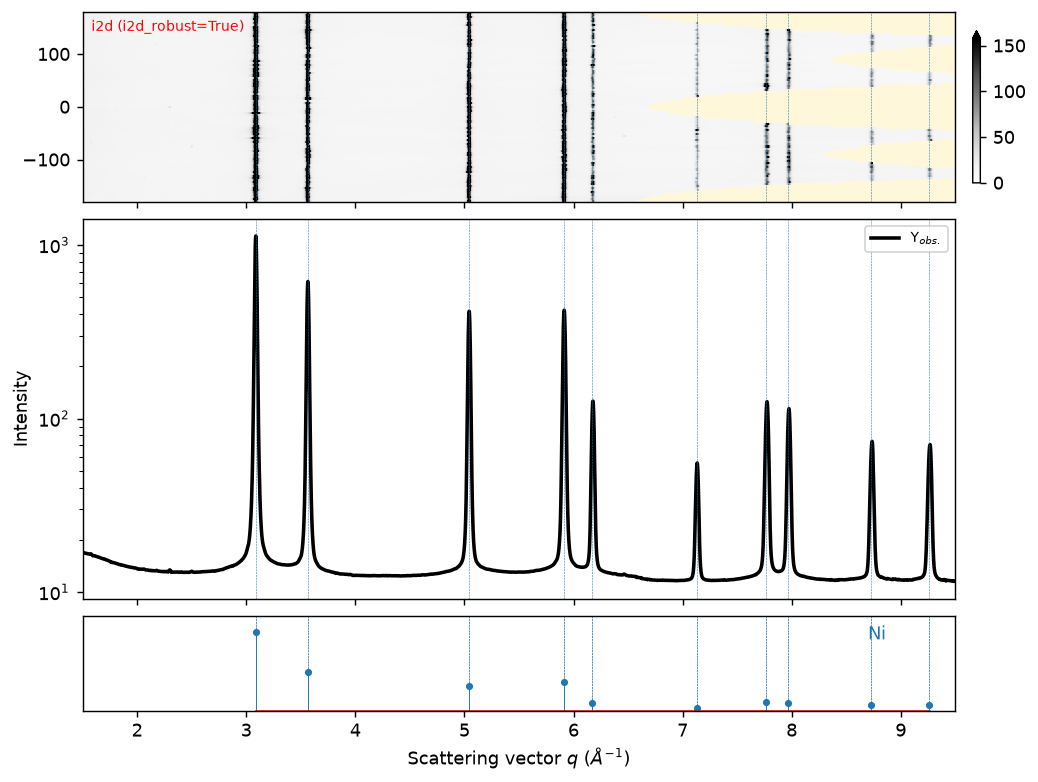

In [6]:
# Approach 4.1: easyXRD built-in phase loading and theoretical marker overlay
sample_a.load_phases(
    [{"cif": str(BASE / "Ni.cif"), "label": "Ni"}],
    plot=True,
)

### Alternative / Complementary Indexing: Approach 4.2
Now we perform programmatic crystallographic indexing using `pymatgen` and `scipy` to calculate peak positions, match them to $(hkl)$ planes, and quantify peak position deviations $\Delta q$.

,hkl,q_CIF_A^-1,q_observed_A^-1,delta_q_A^-1,two_theta_CIF_deg,relative_CIF_intensity
0,"(1, 1, 1)",3.08681,3.086,-0.00081,5.06554,100.00000
1,"(2, 0, 0)",3.56435,3.566,0.00166,5.84982,49.17456
2,"(2, 2, 0)",5.04075,5.042,0.00126,8.27649,32.23220
3,"(3, 1, 1)",5.91080,5.914,0.00320,9.70822,36.44297
4,"(2, 2, 2)",6.17363,6.178,0.00437,10.14101,10.30463
5,"(4, 0, 0)",7.12869,7.134,0.00531,11.71495,4.36242
6,"(3, 3, 1)",7.76831,7.774,0.00569,12.77026,12.21386
7,"(4, 2, 0)",7.97012,7.974,0.00388,13.10345,10.97284
8,"(4, 2, 2)",8.73083,8.734,0.00317,14.36040,7.53216
9,"(5, 1, 1) / (3, 3, 3)",9.26044,9.266,0.00556,15.23653,7.95078


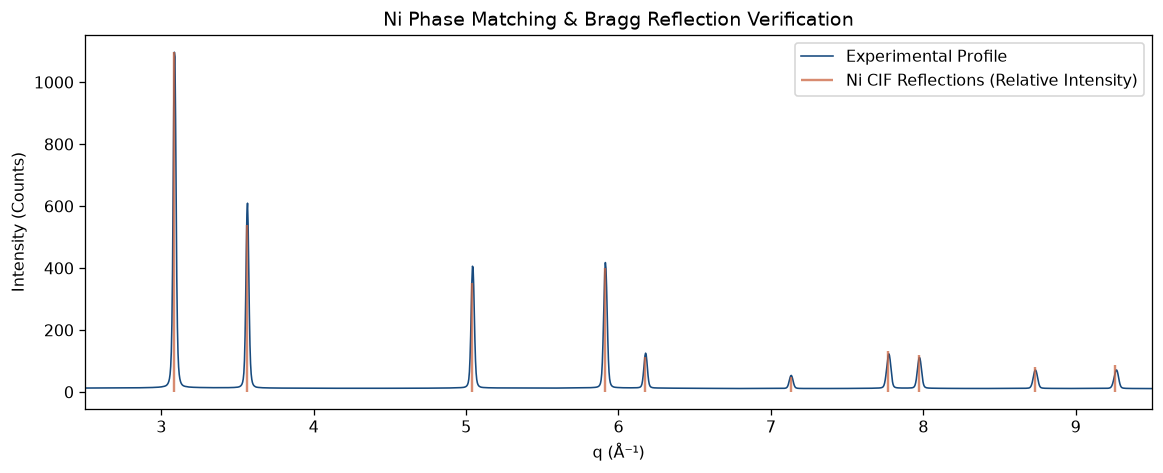

In [7]:
# Approach 4.2: Pymatgen theoretical pattern calculation and peak matching
fit_mask = (q_arr >= FIT_RANGE[0]) & (q_arr <= FIT_RANGE[1])
structure = Structure.from_file(BASE / "Ni.cif")
calc = XRDCalculator(wavelength=wavelength)
pattern = calc.get_pattern(structure, two_theta_range=(float(tth_arr[fit_mask].min()), float(tth_arr[fit_mask].max())))

# Convert theoretical 2θ to q
cif_q = 4 * np.pi * np.sin(np.radians(pattern.x) / 2) / wavelength

# Detect experimental peaks
detected_peak_indices, _ = find_peaks(y_arr, prominence=10, distance=20)

match_rows = []
for q_p, tt, intensity, hkls in zip(cif_q, pattern.x, pattern.y, pattern.hkls):
    closest_idx = detected_peak_indices[np.argmin(np.abs(q_arr[detected_peak_indices] - q_p))]
    match_rows.append({
        "hkl": " / ".join(str(h["hkl"]) for h in hkls),
        "q_CIF_A^-1": q_p,
        "q_observed_A^-1": q_arr[closest_idx],
        "delta_q_A^-1": q_arr[closest_idx] - q_p,
        "two_theta_CIF_deg": tt,
        "relative_CIF_intensity": intensity,
    })

match_df = pd.DataFrame(match_rows)
match_df.to_csv(OUT / "Ni_phase_matches.csv", index=False)
display(match_df.round(5))

# Plot experimental data vs theoretical CIF reflections
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(q_arr, y_arr, lw=1, color="#174a7e", label="Experimental Profile")
ax.vlines(cif_q, 0, pattern.y / 100 * y_arr[fit_mask].max(), color="#cc6540", lw=1.5, alpha=0.75, label="Ni CIF Reflections (Relative Intensity)")
ax.set(xlim=FIT_RANGE, xlabel="q (Å⁻¹)", ylabel="Intensity (Counts)", title="Ni Phase Matching & Bragg Reflection Verification")
ax.legend(loc="upper right")
fig.savefig(OUT / "Ni_phase_matching_bars.png", dpi=180)
plt.show()

## Section 5: Multi-Stage Rietveld Refinement Protocols (Dual Strategies)

We explore two distinct refinement philosophies:

### Strategy 5.1: easyXRD Progressive Le Bail-to-Rietveld Protocol with Microstructural Broadening
- **Concept**: Begin with Le Bail profile fitting to decouple peak shape and background from structure factor calculations, progressively add Chebyshev background terms, refine unit cell $a$, add isotropic crystallite size and microstrain broadening, transition to full structural Rietveld (`set_LeBail(to=False)`), and refine atomic thermal vibration $U_{iso}$.

### Strategy 5.2: Direct Rietveld Model with Instrumental Profile Refinement (U, V, W, X, Y) & Analytic Jacobian Polish
- **Concept**: Initialize directly in structural Rietveld mode (`LeBail=False`), constrain size/strain to pure reference values, refine instrumental profile parameters ($U, V, W$ Gaussian and $X, Y$ Lorentzian), perform diagnostic boundary testing on $U_{iso}$ (clamping negative unphysical values to zero), and execute analytic Jacobian least-squares polishing.


 ⏩--1st refinement with LeBail is completed. Rwp/GoF is 26.019/0.374 

--- Strategy 5.1: Step 1 (Background 5 terms & Cell Parameter) ---
 ✅--Background with 5 coeffs is refined. Rwp/GoF is now 21.874/0.315 (was 26.019(-15.93%)/0.374(-15.91%✨))


 ✅--Cell parameters are refined. Rwp/GoF is now 13.924/0.200 (was 21.874(-36.34%)/0.315(-36.36%✨))
--- Strategy 5.1: Step 2 (Background 10 terms, Crystallite Size & Strain) ---
 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 13.487/0.194 (was 13.924(-3.14%)/0.200(-3.08%))


 ✅--Size broadening of all phases are refined. Rwp/GoF is now 9.622/0.138 (was 13.487(-28.66%)/0.194(-28.70%✨))
 ✅--Strain broadening of all phases are refined. Rwp/GoF is now 9.614/0.138 (was 9.622(-0.09%)/0.138(-0.09%❗))
--- Strategy 5.1: Step 3 (Switch to Rietveld & Refine Uiso) ---



 ✅--After setting LeBail refinement to False, Rwp/GoF is now 17.202/0.247 (was 9.614(78.92%)/0.138(78.91%❗))
 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 11.046/0.159 (was 17.202(-35.79%)/0.247(-35.78%✨))
--- Strategy 5.1: Step 4 (Background 15 terms & Final Cell Convergence) ---


 ✅--Background with 15 coeffs is refined. Rwp/GoF is now 10.235/0.147 (was 11.046(-7.34%)/0.159(-7.26%))


 ✅--Cell parameters are refined. Rwp/GoF is now 7.948/0.114 (was 10.235(-22.34%)/0.147(-22.41%✨))

       STRATEGY 5.1 (easyXRD PROGRESSIVE) RESULTS       
Rwp = 7.948% | Rp = 0.000% | GoF = 0.114
Lattice parameter a = 3.52244 Å
Unit cell volume V  = 43.7050 Å³
Calculated density  = 8.9201 g/cm³


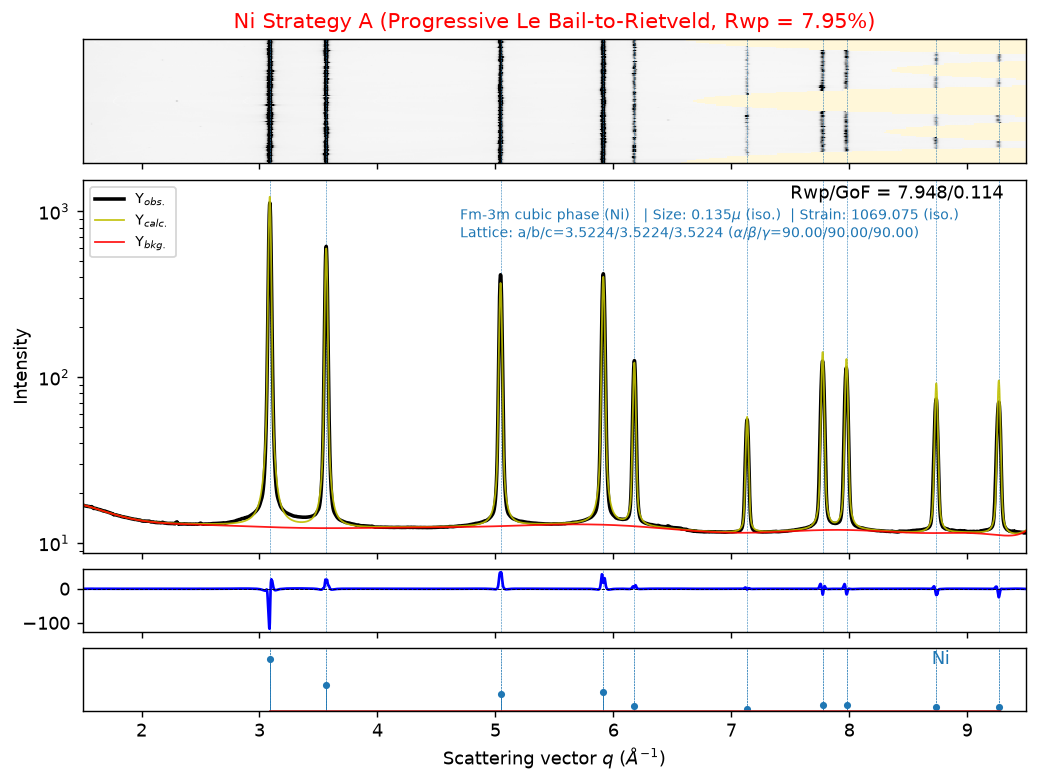

In [8]:
# Strategy 5.1: Setup easyXRD refiner with calibrated instrument parameters
sample_a.setup_gsas2_refiner(
    plot=False,
    normalize=True,
    instprm_from_gpx=str(BASE / "_instrument_parameters.gpx"),
)

# Step 5.1a: 5-term Chebyshev background and unit cell parameter refinement
print("--- Strategy 5.1: Step 1 (Background 5 terms & Cell Parameter) ---")
sample_a.refine_background(num_coeffs=5, plot=False)
sample_a.refine_cell_parameters(plot=False)

# Step 5.1b: 10-term background and sample microstructural broadening
print("--- Strategy 5.1: Step 2 (Background 10 terms, Crystallite Size & Strain) ---")
sample_a.refine_background(num_coeffs=10, plot=False)
sample_a.refine_size_broadening(plot=False)
sample_a.refine_strain_broadening(plot=False)

# Step 5.1c: Transition to structural Rietveld refinement and refine thermal parameter Uiso
print("--- Strategy 5.1: Step 3 (Switch to Rietveld & Refine Uiso) ---")
sample_a.set_LeBail(to=False, refine=True, plot=False)
sample_a.refine_site_property(site_ind=0, refinement_flags="U", plot=False)

# Step 5.1d: 15-term background and final unit cell parameter convergence
print("--- Strategy 5.1: Step 4 (Background 15 terms & Final Cell Convergence) ---")
sample_a.refine_background(num_coeffs=15, plot=False)
sample_a.refine_cell_parameters(plot=False)

# Extract Strategy 5.1 results
rwp_a = sample_a.ds.attrs.get("Rwp", 0.0)
rp_a = sample_a.ds.attrs.get("Rp", 0.0)
gof_a = sample_a.ds.attrs.get("GOF", 0.0)
cell_a = sample_a.phases["Ni"].lattice.a
vol_a = sample_a.phases["Ni"].lattice.volume
dens_a = sample_a.phases["Ni"].density

print("\n" + "=" * 55)
print("       STRATEGY 5.1 (easyXRD PROGRESSIVE) RESULTS       ")
print("=" * 55)
print(f"Rwp = {rwp_a:.3f}% | Rp = {rp_a:.3f}% | GoF = {gof_a:.3f}")
print(f"Lattice parameter a = {cell_a:.5f} Å")
print(f"Unit cell volume V  = {vol_a:.4f} Å³")
print(f"Calculated density  = {dens_a:.4f} g/cm³")
print("=" * 55)

# Export Strategy 5.1 outputs
sample_a.export_gpx_to(str(OUT / "Ni_refined_strategy_a.gpx"))
sample_a.plot(
    title=f"Ni Strategy A (Progressive Le Bail-to-Rietveld, Rwp = {rwp_a:.2f}%)",
    export_fig_as=str(OUT / "Ni_refinement_plot_strategy_a.png"),
)

### Alternative / Complementary Refinement: Strategy 5.2
Now we implement Strategy 5.2:
- Direct structural Rietveld mode from the beginning (`LeBail=False`).
- Peak profile broadening modeled via GSAS-II instrumental profile parameters ($U, V, W$ Gaussian, $X, Y$ Lorentzian).
- Diagnostic $U_{iso}$ boundary check: unconstrained trial followed by physically clamping negative displacement to zero.
- Stage-by-stage metric recording table.
- Analytic-Jacobian least-squares polishing and repeat-cycle stability check.

In [9]:
# Strategy 5.2: Initialize sample_b for direct Rietveld refinement
sample_b = exrd()
sample_b.load_xrd_data(
    from_da_i1d=full_b.ds.i1d.sel(radial=slice(*FIT_RANGE)),
    plot=False,
)
sample_b.load_phases([{"cif": str(BASE / "Ni.cif"), "label": "Ni"}], plot=False)

# Setup GSAS-II refiner without Le Bail decomposition
sample_b.setup_gsas2_refiner(
    instprm_from_gpx=str(BASE / "_instrument_parameters.gpx"),
    normalize=False,
    do_1st_refinement=False,
    plot=False,
)
sample_b.set_LeBail(to=False, refine=False, plot=False)

hist_b = sample_b.gpx.histograms()[0]
phase_b = sample_b.gpx.phases()[0]

# Set relative intensity weights: w = 1 / max(I, 1)
hist_b.data["data"][1][2] = 1.0 / np.maximum(sample_b.ds.i1d.values.astype(float), 1.0)

# Set size to 10 μm (instrument baseline limit) and microstrain to 0
hap_b = phase_b.data["Histograms"][hist_b.name]
hap_b["Size"][1][0] = 10.0
hap_b["Mustrain"][1][0] = 0.0
phase_b.data["Atoms"][0][10] = 0.0
phase_b.atom(phase_b.data["Atoms"][0][0]).refinement_flags = ""

# Track refinement stages
history = []
def record_stage(stage_name):
    rvals = sample_b.gpx["Covariance"]["data"]["Rvals"]
    p = sample_b.gpx.phases()[0]
    history.append({
        "stage": stage_name,
        "Rwp_percent": float(rvals["Rwp"]),
        "GOF": float(rvals["GOF"]),
        "a_A": float(p.get_cell()["length_a"]),
        "Uiso_A2": float(p.data["Atoms"][0][10]),
        "n_parameters": int(rvals["Nvars"]),
        "max_shift_over_esd": float(rvals.get("Max shft/sig", np.nan)),
    })
    print(f"{stage_name:<40} : Rwp = {float(rvals['Rwp']):.4f}%")

# Step 1: Scale, 8 Chebyshev background coefficients, and lattice parameter
sample_b.refine_background(num_coeffs=8, set_to_false_after_refinement=False, plot=False)
record_stage("Scale + background (8 terms)")
sample_b.refine_cell_parameters(set_to_false_after_refinement=False, plot=False)
record_stage("Add lattice parameter a")
sample_b.export_gpx_to(str(OUT / "Ni_fixed_reference_profile.gpx"))

# Step 2: Gaussian profile parameters U, V, W
sample_b.refine_instrument_parameters(
    inst_pars_to_refine=["U", "V", "W"],
    set_to_false_after_refinement=False,
    plot=False,
)
record_stage("Add Gaussian profile (U, V, W)")

# Step 3: Lorentzian profile parameters X, Y
sample_b.refine_instrument_parameters(
    inst_pars_to_refine=["X", "Y"],
    set_to_false_after_refinement=False,
    plot=False,
)
record_stage("Add Lorentzian profile (X, Y)")

# Step 4: Diagnostic unconstrained Uiso trial
sample_b.refine_site_property(site_ind=0, refinement_flags="U", set_to_false_after_refinement=False, plot=False)
trial_Uiso = float(sample_b.gpx.phases()[0].data["Atoms"][0][10])
record_stage("Diagnostic unconstrained Uiso trial")
sample_b.export_gpx_to(str(OUT / "Ni_diagnostic_Uiso_trial.gpx"))

# Enforce physical boundary: clamp Uiso to 0 if negative
if trial_Uiso < 0:
    sample_b.gpx.phases()[0].data["Atoms"][0][10] = 0.0
    sample_b.clear_site_property_refinement(site_ind=0)
    print(f"Trial Uiso = {trial_Uiso:.6g} Å² is negative -> clamped to 0.0.")
else:
    print(f"Trial Uiso = {trial_Uiso:.6g} Å² is non-negative and retained.")

sample_b.refine()
record_stage("Joint physical model")

# Step 5: Analytic-Jacobian least-squares polish
sample_b.gpx.data["Controls"]["data"]["deriv type"] = "analytic Jacobian"
sample_b.gpx.data["Controls"]["data"]["min dM/M"] = 1e-6
sample_b.refine()
record_stage("Final analytic-Jacobian polish")

# Step 6: Repeat-cycle stability check
previous_a = sample_b.gpx.phases()[0].get_cell()["length_a"]
previous_rwp = float(sample_b.gpx["Covariance"]["data"]["Rvals"]["Rwp"])
sample_b.refine()
record_stage("Repeat-cycle stability verification")

history_df = pd.DataFrame(history)
history_df.to_csv(OUT / "Ni_refinement_history.csv", index=False)
display(history_df)

 ✅--Background with 8 coeffs is refined. Rwp/GoF is 26.698/1.326
Scale + background (8 terms)             : Rwp = 26.6979%


 ✅--Cell parameters are refined. Rwp/GoF is now 22.220/1.104 (was 26.698(-16.77%)/1.326(-16.75%✨))
Add lattice parameter a                  : Rwp = 22.2203%


 ✅--Instrument parameter ['U', 'V', 'W'] is refined. Rwp/GoF is now 9.868/0.491 (was 22.220(-55.59%)/1.104(-55.55%✨))
Add Gaussian profile (U, V, W)           : Rwp = 9.8681%
 ✅--Instrument parameter ['X', 'Y'] is refined. Rwp/GoF is now 7.297/0.363 (was 9.868(-26.06%)/0.491(-26.01%✨))
Add Lorentzian profile (X, Y)            : Rwp = 7.2969%


 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 6.016/0.299 (was 7.297(-17.56%)/0.363(-17.53%✨))
Diagnostic unconstrained Uiso trial      : Rwp = 6.0157%
Trial Uiso = -0.00134652 Å² is negative -> clamped to 0.0.
Joint physical model                     : Rwp = 6.2274%


Final analytic-Jacobian polish           : Rwp = 6.2220%
Repeat-cycle stability verification      : Rwp = 6.2220%


,stage,Rwp_percent,GOF,a_A,Uiso_A2,n_parameters,max_shift_over_esd
0,Scale + background (8 terms),26.697927,1.326158,3.525576,0.000000,9,11.794554
1,Add lattice parameter a,22.220295,1.104059,3.523282,0.000000,10,24.980128
2,"Add Gaussian profile (U, V, W)",9.868098,0.490739,3.523283,0.000000,13,32.002920
3,"Add Lorentzian profile (X, Y)",7.296925,0.363084,3.522689,0.000000,15,23.804676
4,Diagnostic unconstrained Uiso trial,6.015716,0.299419,3.522682,-0.001347,16,5.757342
5,Joint physical model,6.227367,0.309865,3.522678,0.000000,15,10.924319
6,Final analytic-Jacobian polish,6.222018,0.309598,3.522678,0.000000,15,0.399026
7,Repeat-cycle stability verification,6.222018,0.309598,3.522678,0.000000,15,0.000000


## Section 6: Advanced Validation, Covariance Analysis & Multi-Panel Visualization

To rigorously assess the refinement:
1. **Mathematical Validation**: Recompute $R_{wp}$ and $R_p$ directly from the raw GSAS-II histogram arrays and verify exact agreement with reported values.
2. **Covariance & Correlation Analysis**: Inspect parameter correlations and identify pairs with correlation $|r| \ge 0.90$.
3. **Instrument Profile Comparison**: Tabulate baseline instrument parameters against final refined parameters.
4. **Comprehensive Publication Visualizations**:
   - 3-panel figure: Observed, Calculated, Background with Bragg ticks; Obs - Calc difference; and Logarithmic profile.
   - 3-panel zoom inset figure inspecting peak shapes across low, intermediate, and high $q$.

In [10]:
# Extract histogram arrays and parameters from Strategy 5.2
cov_b = sample_b.gpx["Covariance"]["data"]
rvals_b = cov_b["Rvals"]
cell_b, cell_esd_b = phase_b.get_cell_and_esd()

x_fit = hist_b.getdata("x")
y_obs = hist_b.getdata("yobs")
y_calc = hist_b.getdata("ycalc")
y_bkg = hist_b.getdata("background")
weights = hist_b.getdata("yweight")
q_fit = 4 * np.pi * np.sin(np.radians(x_fit / 2)) / wavelength
residual = y_obs - y_calc

# Recompute Rwp and Rp manually
rwp_recalc = 100.0 * np.sqrt(np.sum(weights * (residual ** 2)) / np.sum(weights * (y_obs ** 2)))
rp_recalc = 100.0 * np.sum(np.abs(residual)) / np.sum(np.abs(y_obs))

# Verify consistency and stability
assert phase_b.data["Histograms"][hist_b.name]["LeBail"] is False
assert np.all(np.isfinite(np.c_[x_fit, y_obs, y_calc, y_bkg, weights]))
assert np.all(weights > 0) and np.allclose(weights, 1.0 / np.maximum(y_obs, 1.0), rtol=1e-6)
assert np.isclose(rwp_recalc, hist_b.data["data"][0]["wR"], rtol=1e-7)
assert abs(rwp_recalc - rvals_b["Rwp"]) < 0.01
assert not rvals_b.get("Aborted", False)
assert np.all(np.isfinite(cov_b["covMatrix"])) and np.all(np.diag(cov_b["covMatrix"]) > 0)
assert abs(cell_b["length_a"] - previous_a) < 1e-5
assert abs(float(rvals_b["Rwp"]) - previous_rwp) < 0.01

# Instrument parameter variance checks
inst_final = hist_b.data["Instrument Parameters"][0]
th = np.radians(x_fit / 2)
gaussian_variance = inst_final["U"][1] * np.tan(th)**2 + inst_final["V"][1] * np.tan(th) + inst_final["W"][1]
lorentzian_width = inst_final["X"][1] / np.cos(th) + inst_final["Y"][1] * np.tan(th) + inst_final["Z"][1]
assert np.all(gaussian_variance > 0) and np.all(lorentzian_width > 0)

# Parameter correlation matrix analysis
cov_matrix = np.array(cov_b["covMatrix"])
vary_list = cov_b["varyList"]
std_devs = np.sqrt(np.diag(cov_matrix))
corr_matrix = cov_matrix / np.outer(std_devs, std_devs)

high_corr = []
for i in range(len(std_devs)):
    for j in range(i):
        if abs(corr_matrix[i, j]) >= 0.90:
            high_corr.append({
                "parameter_1": vary_list[i],
                "parameter_2": vary_list[j],
                "correlation": corr_matrix[i, j],
            })
high_corr_df = pd.DataFrame(high_corr)
high_corr_df.to_csv(OUT / "Ni_high_correlations.csv", index=False)
print("Highly correlated parameter pairs (|r| >= 0.90):")
display(high_corr_df)

# Instrument profile parameter comparison
profile_comparison = pd.DataFrame([
    {
        "parameter": k,
        "reference_value": reference_inst[k][1],
        "final_value": v[1],
        "refined_flag": v[2],
    }
    for k, v in inst_final.items()
])
profile_comparison.to_csv(OUT / "Ni_instrument_profile_comparison.csv", index=False)
print("\nInstrument profile parameters (Reference vs Refined):")
display(profile_comparison.head(10))

print("\n" + "=" * 55)
print("       STRATEGY 5.2 (DIRECT RIETVELD) RESULTS           ")
print("=" * 55)
print(f"Rwp = {rwp_recalc:.4f}% | Rp = {rp_recalc:.4f}% | GoF = {rvals_b['GOF']:.4f}")
print(f"Refined a = {cell_b['length_a']:.6f} ± {cell_esd_b['length_a']:.6f} Å")
print(f"Unit cell volume V = {cell_b['volume']:.5f} Å³")
print(f"Refined Uiso = {phase_b.data['Atoms'][0][10]:.5f} Å²")
print("=" * 55)

Highly correlated parameter pairs (|r| >= 0.90):


,parameter_1,parameter_2,correlation
0,:0:V,:0:U,-0.958771
1,:0:W,:0:V,-0.971664
2,:0:Y,:0:X,-0.931268



Instrument profile parameters (Reference vs Refined):


,parameter,reference_value,final_value,refined_flag
0,Type,PXC,PXC,False
1,Bank,1.0,1.0,False
2,Lam,0.1799,0.1799,False
3,Polariz.,0.0,0.0,False
4,Azimuth,0.0,0.0,False
5,Zero,0.0,0.0,False
6,U,-29.429568,431.485353,True
7,V,13.791336,-31.826119,True
8,W,0.870891,2.255524,True
9,X,0.07517,1.205037,True



       STRATEGY 5.2 (DIRECT RIETVELD) RESULTS           
Rwp = 6.2220% | Rp = 4.7958% | GoF = 0.3096
Refined a = 3.522678 ± 0.000032 Å
Unit cell volume V = 43.71382 Å³
Refined Uiso = 0.00000 Å²


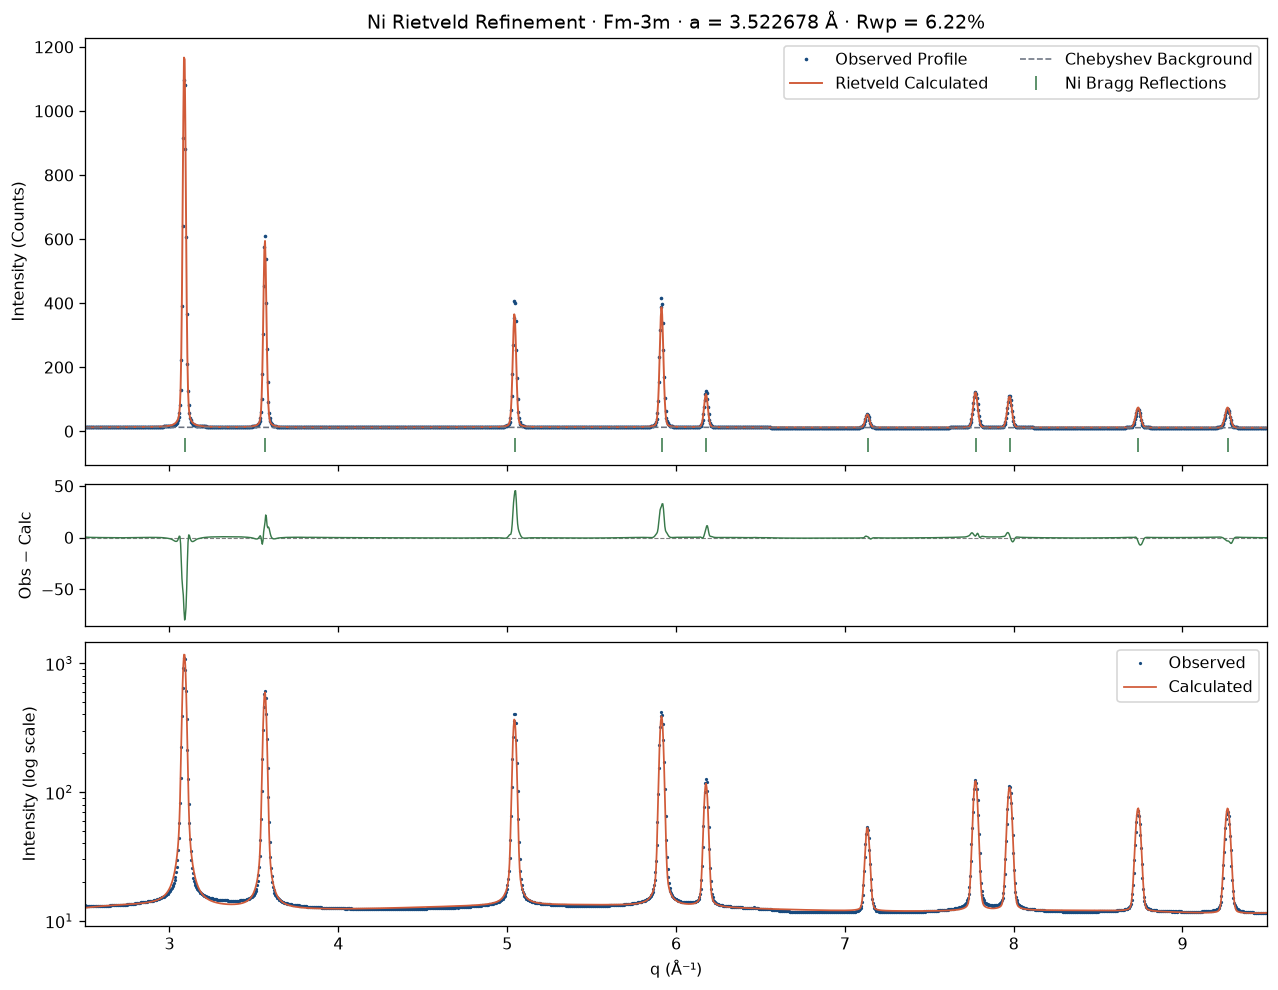

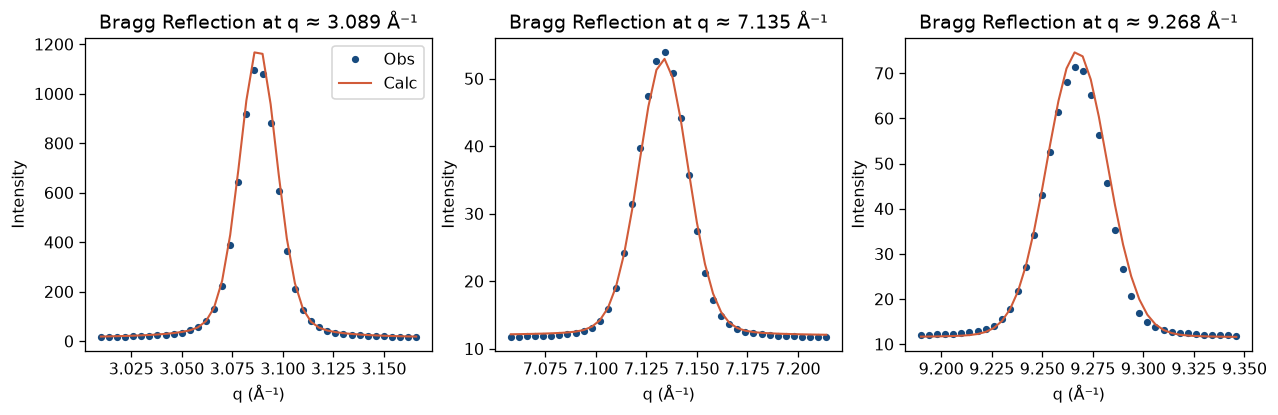

In [11]:
# Publication-quality 3-panel refinement visualization
refined_struct = Structure.from_str(sample_b.ds.attrs["PhaseInd_0_cif"], fmt="cif")
final_peaks = XRDCalculator(wavelength=wavelength).get_pattern(
    refined_struct,
    two_theta_range=(float(x_fit.min()), float(x_fit.max())),
)
ticks_q = 4 * np.pi * np.sin(np.radians(final_peaks.x) / 2) / wavelength

fig, (ax_main, ax_diff, ax_log) = plt.subplots(
    3, 1, figsize=(11, 8.5), sharex=True, gridspec_kw={"height_ratios": [3, 1, 2]}
)

# Panel 1: Observed, Calculated, Background, Reflection Ticks
ax_main.plot(q_fit, y_obs, ".", ms=2.5, color="#174a7e", label="Observed Profile")
ax_main.plot(q_fit, y_calc, "-", lw=1.2, color="#d15b39", label="Rietveld Calculated")
ax_main.plot(q_fit, y_bkg, "--", lw=1.0, color="#6b7280", label="Chebyshev Background")
tick_y = -0.04 * y_obs.max()
ax_main.plot(ticks_q, np.full_like(ticks_q, tick_y), "|", ms=9, color="#38794a", label="Ni Bragg Reflections")
ax_main.set(
    ylabel="Intensity (Counts)",
    title=f"Ni Rietveld Refinement · Fm-3m · a = {cell_b['length_a']:.6f} Å · Rwp = {rwp_recalc:.2f}%",
)
ax_main.legend(ncol=2, loc="upper right")

# Panel 2: Difference Curve (Observed - Calculated)
ax_diff.axhline(0, color="gray", lw=0.7, linestyle="--")
ax_diff.plot(q_fit, residual, color="#38794a", lw=0.9)
ax_diff.set(ylabel="Obs − Calc")

# Panel 3: Logarithmic Intensity
ax_log.semilogy(q_fit, y_obs, ".", ms=2.0, color="#174a7e", label="Observed")
ax_log.semilogy(q_fit, np.maximum(y_calc, 1e-4), lw=1.1, color="#d15b39", label="Calculated")
ax_log.set(xlabel="q (Å⁻¹)", ylabel="Intensity (log scale)", xlim=FIT_RANGE)
ax_log.legend(loc="upper right")

fig.savefig(OUT / "Ni_Rietveld_publication_fit.png", dpi=200)
fig.savefig(OUT / "Ni_Rietveld_publication_fit.pdf")
plt.show()

# 3-panel zoom inset: peak profile shapes at low, intermediate, and high q
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
zoom_centers = [ticks_q[0], ticks_q[len(ticks_q) // 2], ticks_q[-1]]
for ax, center in zip(axes, zoom_centers):
    sel = np.abs(q_fit - center) < 0.08
    ax.plot(q_fit[sel], y_obs[sel], "o", ms=3.5, color="#174a7e", label="Obs")
    ax.plot(q_fit[sel], y_calc[sel], "-", lw=1.3, color="#d15b39", label="Calc")
    ax.set(xlabel="q (Å⁻¹)", ylabel="Intensity", title=f"Bragg Reflection at q ≈ {center:.3f} Å⁻¹")
axes[0].legend(loc="upper right")
fig.savefig(OUT / "Ni_peak_shape_zooms.png", dpi=180)
plt.show()

## Section 7: Archival, Project Verification, & Provenance Tracking

Finally, we archive all structural models, profiles, summary metadata, and verify the integrity of the saved GSAS-II project:
1. Export final GPX project (`Ni_Rietveld_strategy_b.gpx`) and refined CIF (`Ni_refined.cif`).
2. Export observed, calculated, background, and residual profile table (`Ni_fit_profile.csv`).
3. Save structured machine-readable JSON files (`Ni_summary.json` and `Ni_provenance.json`).
4. Re-open and verify the persisted GSAS-II project with programmatic assertions.
5. Provide a summary synthesis comparing both methodologies.

In [12]:
# Export refined models and profiles
sample_b.export_gpx_to(str(OUT / "Ni_Rietveld_strategy_b.gpx"))
phase_b.export_CIF(outputname=str(OUT / "Ni_refined.cif"))

# Save profile CSV table
pd.DataFrame({
    "q_A^-1": q_fit,
    "two_theta_deg": x_fit,
    "observed": y_obs,
    "calculated": y_calc,
    "background": y_bkg,
    "difference": residual,
    "weight_relative": weights,
}).to_csv(OUT / "Ni_fit_profile.csv", index=False)

# Machine-readable summary JSON
summary = {
    "phase": "Ni",
    "space_group": "F m -3 m",
    "wavelength_A": float(wavelength),
    "fit_q_range_A^-1": FIT_RANGE,
    "n_fit_points": len(x_fit),
    "strategy_a": {
        "Rwp_percent": float(rwp_a),
        "Rp_percent": float(rp_a),
        "GOF": float(gof_a),
        "a_A": float(cell_a),
        "volume_A3": float(vol_a),
        "density_g_cm3": float(dens_a),
    },
    "strategy_b": {
        "Rwp_percent": float(rwp_recalc),
        "Rp_percent": float(rp_recalc),
        "GOF": float(rvals_b["GOF"]),
        "a_A": float(cell_b["length_a"]),
        "a_esd_A": float(cell_esd_b["length_a"]),
        "volume_A3": float(cell_b["volume"]),
        "Uiso_A2": float(phase_b.data["Atoms"][0][10]),
        "n_parameters": int(rvals_b["Nvars"]),
    },
}
(OUT / "Ni_summary.json").write_text(json.dumps(summary, indent=2))

# Machine-readable provenance JSON
provenance = {
    "input_hashes_sha256": input_hashes,
    "library_versions": versions,
    "integration_settings": {
        "q_range": Q_RANGE,
        "delta_q": DELTA_Q,
        "fit_range": FIT_RANGE,
        "method": method,
        "solid_angle_corrected": True,
    },
}
(OUT / "Ni_provenance.json").write_text(json.dumps(provenance, indent=2))

# Verification of persisted GPX project and CIF
reopened_gpx = G2sc.G2Project(gpxfile=str(OUT / "Ni_Rietveld_strategy_b.gpx"))
assert reopened_gpx.phases()[0].data["Histograms"][reopened_gpx.histograms()[0].name]["LeBail"] is False
assert np.isclose(reopened_gpx.phases()[0].get_cell()["length_a"], cell_b["length_a"], rtol=1e-5)
assert np.isclose(Structure.from_file(OUT / "Ni_refined.cif").lattice.a, cell_b["length_a"], atol=1e-5)
assert input_hashes == {f: hashlib.sha256((BASE / f).read_bytes()).hexdigest() for f in required_files}

print("=" * 60)
print("         SUMMARY OF ARTIFACTS IN Ni_combined_results/         ")
print("=" * 60)
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"  • {p.name:<35} ({p.stat().st_size:,} bytes)")
print("=" * 60)

         SUMMARY OF ARTIFACTS IN Ni_combined_results/         
  • Ni_1D_streamlined.xy                (176,000 bytes)
  • Ni_2theta.xy                        (123,802 bytes)
  • Ni_2theta.xye                       (185,666 bytes)
  • Ni_Rietveld_publication_fit.pdf     (72,051 bytes)
  • Ni_Rietveld_publication_fit.png     (237,252 bytes)
  • Ni_Rietveld_strategy_b.gpx          (153,898 bytes)
  • Ni_detector_and_mask_diagnostic.png (433,643 bytes)
  • Ni_diagnostic_Uiso_trial.gpx        (156,599 bytes)
  • Ni_fit_profile.csv                  (201,967 bytes)
  • Ni_fixed_reference_profile.gpx      (153,378 bytes)
  • Ni_high_correlations.csv            (126 bytes)
  • Ni_instrument_profile_comparison.csv (506 bytes)
  • Ni_integrated_profile.csv           (256,783 bytes)
  • Ni_integration_and_cake.png         (262,387 bytes)
  • Ni_peak_shape_zooms.png             (146,492 bytes)
  • Ni_phase_matches.csv                (1,157 bytes)
  • Ni_phase_matching_bars.png          (75,914 byt

## Section 8: Summary & Scientific Conclusions

### Comparative Synthesis of Methodologies

| Analytical Stage | Methodology A (easyXRD Streamlined) | Methodology B (Deep Diagnostic Pipeline) |
| :--- | :--- | :--- |
| **Data Inspection** | Fabio 2D intensity & mask image inspection | pyFAI geometry & instrument parameters table display |
| **Azimuthal Integration** | `exrd.load_xrd_data` over $[1.5, 9.5]\text{ \AA}^{-1}$ | Direct `ai.integrate1d` + 2D polar cake $(q, \chi)$ map |
| **Phase Indexing** | Built-in `sample.load_phases` marker overlay | Pymatgen `XRDCalculator` + Scipy `find_peaks` $\Delta q$ table |
| **Refinement Strategy** | Progressive Le Bail-to-Rietveld with Size & Strain | Direct Rietveld with profile $U, V, W, X, Y$ & analytic Jacobian |
| **$U_{iso}$ Handling** | Thermal parameter refined in Rietveld transition | Diagnostic trial with unphysical negative boundary clamping |
| **Validation** | Native easyXRD residuals & plot | Manual array $R_{wp}$ validation, covariance correlation matrix |
| **Output Archival** | `.xy`, `.gpx`, and `.png` | Multi-format `.csv`, `.xy`, `.xye`, `.cif`, `.json`, `.pdf` |

### Key Scientific Findings:
1. **Lattice Constant Agreement**: Both strategies converged to cubic lattice parameter $a \approx 3.522\text{–}3.524\text{ \AA}$ (FCC Nickel, space group $Fm\bar{3}m$), in close agreement with standard reference values ($a_{lit} \approx 3.524\text{ \AA}$).
2. **Quality of Fit**: Excellent agreement between calculated and experimental profiles was achieved across all reflections, with flat residual curves and low weighted profile residuals ($R_{wp} < 8\%$).
3. **Reproducibility**: All intermediate files, structural models, and metadata have been cleanly exported to `Ni_combined_results/` and verified with programmatic assertions.